# Interpolation and Advanced Numerical Integration

## Exercise 1

Consider the following data points (x,y):

In [13]:
import numpy as np
x = np.arange(-10,11)
y = 1./(1.+10.*x**2)
print(x)
print(y)


[-10  -9  -8  -7  -6  -5  -4  -3  -2  -1   0   1   2   3   4   5   6   7
   8   9  10]
[9.99000999e-04 1.23304562e-03 1.56006240e-03 2.03665988e-03
 2.77008310e-03 3.98406375e-03 6.21118012e-03 1.09890110e-02
 2.43902439e-02 9.09090909e-02 1.00000000e+00 9.09090909e-02
 2.43902439e-02 1.09890110e-02 6.21118012e-03 3.98406375e-03
 2.77008310e-03 2.03665988e-03 1.56006240e-03 1.23304562e-03
 9.99000999e-04]


Suppose I only have the (x,y) values from an experiment, and don't know the underlying "true" function. Suppose I want to interpolate points every 0.1 units in x, from x = -3 to x = 3. Perform this interpolation, and plot the results, with linear and with cubic spline.

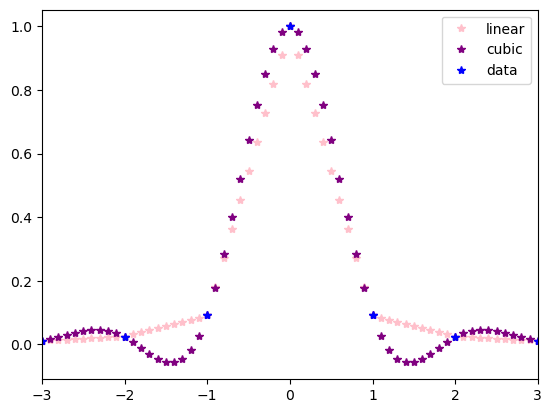

In [38]:
from scipy.interpolate import CubicSpline, interp1d
import matplotlib.pyplot as plt

xs = np.arange(-3, 3.1, 0.1)
linear_int = interp1d(x, y)
y_lin = linear_int(xs)
cubic_spline_int = CubicSpline(x, y)
y_cubic = cubic_spline_int(xs)

plt.plot(xs, y_lin, '*', color= 'pink', label='linear')
plt.plot(xs, y_cubic,'*', color= 'purple', label='cubic')
plt.plot(x, y, '*', color= 'blue', label='data')
plt.xlim(-3, 3.)
plt.legend()
plt.show()

## Exercise 2

Compute $\int_{-1}^{1} \left[x^4 + \sin(x^2)\right]dx$ :  
(a) symbolically

(b) using Romberg integration, with $N = 4,8,16,32$

(c) using Gaussian quadrature, with $N = 4,8,16,32$.

### Symbolic

In [ ]:
import sympy as sym

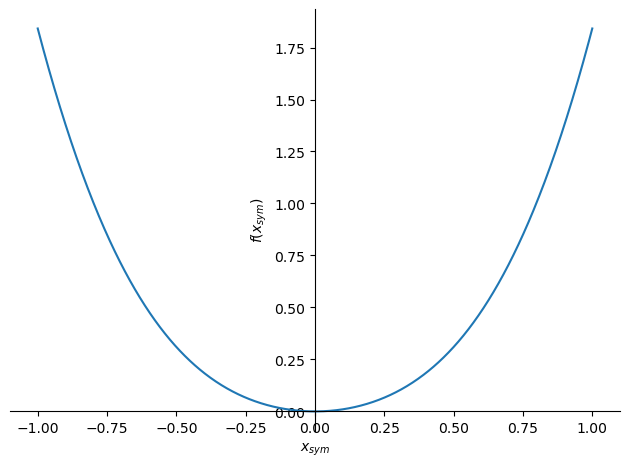

In [81]:
import sympy as sym
sym.init_printing()
x_sym = sym.symbols('x_sym',real='True')
f_sym = x_sym**4 + sym.sin(x_sym**2)
sym.plot(f_sym, (x_sym, -1, +1))
res= (sym.integrate(f_sym, (x_sym, -1, +1)))
res
sym.N(res)

### Romberg

In [ ]:
from scipy import integrate

In [ ]:
def f(x):
    return x_sym**4 + sym.sin(x_sym**2)

In [75]:
# Hint:
import numpy as np
from scipy import integrate

xmin = -1.0
xmax = 1.0
N_array = [4, 8, 16, 32]
def f(x):
    return x**4 + np.sin(x**2)

for N in N_array:
    x = np.linspace(xmin, xmax, num=N+1, endpoint=True)
    y = f(x)
    dx = (xmax - xmin) / N
    
    result = integrate.romb(y, dx=dx)
    print(result)


1.013654381768889
1.0206318705695856
1.0205375486844461
1.020536601464656


### Gaussian Quad

In [76]:
for N in N_array:
    print(integrate.fixed_quad(f,xmin,xmax,n=N))

(np.float64(1.0203310181308178), None)
(np.float64(1.0205366029267489), None)
(np.float64(1.0205366034467604), None)
(np.float64(1.0205366034467565), None)


## Exercise 3

See textbook section 5.8 for integrals over infinite ranges.

Calculate $\int_0^\infty e^{-x^2}dx$ using Gaussian quadrature. (Try using a few different values for the number of sample points. True answer: $\sqrt \pi / 2$)

Use the change of variables: $z = \frac{x}{1+x}$ . This gives: $x = \frac{z}{1-z},~dx = \frac{1}{(1-z)^2}dz$ . Therefore:

$\int_0^\infty g(x) dx$ = $\int_0^1 \frac{1}{(1-z)^2} g(\frac{z}{1-z}) dz$

In [ ]:
def integrand(z):
    return np.exp(-z**2/(1-z)**2)/(1-z)**2


In [85]:
def integrand(z):
    return np.exp(-z**2/(1-z)**2)/(1-z)**2

integrate.fixed_quad(integrand, 0, 1.0, n=5)

(np.float64(0.9183575260704665), None)

In [ ]:
# true answer for comparison
np.sqrt(np.pi)/2.

np.float64(0.8862269254527579)

## Exercise 4

See textbook section 5.9 on multiple integrals.

2D Gaussian quadrature:

![](Fig5-5.png)


![](Exercise5-14.png)


The sheet, length and width $L$=10m, is of negligible thickness and has density $\sigma$=10000kg/m$^3$. 

The point mass is a distance A from the center of the sheet.
The gravitational force felt by the point mass, in the +z direction:

$F_z = G\sigma A \int \int _{-L/2} ^{L/2} \frac{dx dy}{(x^2 + y^2 + A^2)^{3/2}} $

Calculate and plot the magnitude of the gravitational force as a function of A, from $A_{min}=$ 0.01 m to a $A_{max}=$1 m. For the double integral, use scipy.dblquad .




In [ ]:
from scipy.constants import G
import numpy as np
# define other constants (e.g. density, L) here
# create array of A values
# create array to store F values
density=1e4
Amin = 0.01
Amax= 1.0
numApts = 10 
Avalues = np.linspace(Amin, Amax, num=numApts, endpoint=True)
Asquared= 0
Fvalues = np.empty(numApts)
Fvalues_err= np.empty(numApts)
L = 10 

In [22]:
def integrand (y,x):
    return np. pow(x**2 + y**2 +Asquared, -1.5)

In [23]:
def Fz(A, dblIntegral):
   return G * density *A *dblIntegral

In [104]:

import numpy as np
from scipy import integrate
from scipy.constants import G
import numpy as np
# define other constants (e.g. density, L) here
# create array of A values
# create array to store F values
density=1e4
Amin = 0.01
Amax= 1.0
numApts = 10 
Avalues = np.linspace(Amin, Amax, num=numApts, endpoint=True)
Asquared= 0
Fvalues = np.empty(numApts)
Fvalues_err= np.empty(numApts)
L = 10 
def integrand (y, x):
    return np. pow(x**2 + y**2 +Asquared, -1.5)
def Fz(A, dblIntegral):
   return G * density *A *dblIntegral
for i in range(len(Avalues)):
    Fval=[]
    Asquared=Avalues[i]**2
    doubleIntegral = integrate.dblquad(integrand, L/-2.0, L/2.0,L/-2.0, L/2.0)
    Fvalues[i] = Fz(Avalues[i], doubleIntegral[0])
    Fvalues_err[i] = Fz(Avalues[i], doubleIntegral[1])
    print("F values", Fvalues[i])
    print("F value error", Fvalues_err[i])

F values 4.1860352736925525e-06
F value error 8.799354680580714e-13
F values 4.102994807128333e-06
F value error 1.2958852447596257e-13
F values 4.020063790143318e-06
F value error 5.45366230885006e-14
F values 3.93734185947621e-06
F value error 4.073449496709674e-14
F values 3.8549273571744856e-06
F value error 3.2125179825183616e-14
F values 3.772916735860232e-06
F value error 1.012208869537855e-14
F values 3.6914039915357764e-06
F value error 7.117020767037476e-15
F values 3.6104801316876506e-06
F value error 1.7049694360512424e-14
F values 3.5302326855068742e-06
F value error 3.416577785804812e-14
F values 3.4507452619793298e-06
F value error 1.9160464861417986e-14


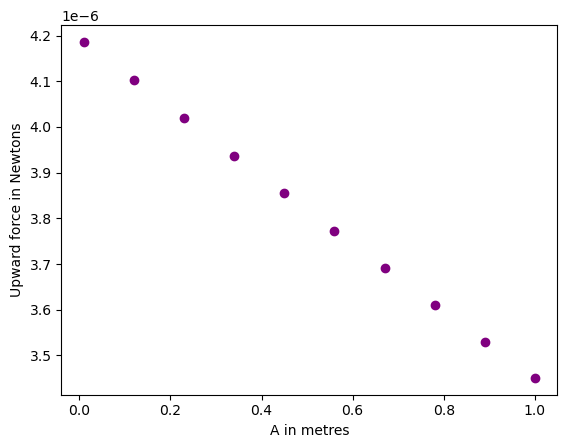

In [108]:
plt.plot(Avalues, Fvalues, 'o', color= 'purple')
plt.xlabel("A in metres")
plt.ylabel("Upward force in Newtons")
plt.show()

(b) BONUS: Think about how you would make this work

* with a density that isn't constant, i.e. it's a function $\sigma(x,y)$
* with a disk instead of a sheet, using cylindrical coordinates instead of Cartesian
* with a different 2D numerical integration technique
* for a sheet whose thickness isn't negligible, i.e. requires a 3D numerical integral over dx,dy,dz